# plutovizu — Catalogue matplotlib

API chaînable : chaque méthode retourne le graphique, on enchaîne les appels et on termine par `.show()`. Le thème **editorial** est appliqué dès l'import. Fiches détaillées (données attendues, paramètres) dans la [documentation](https://mr-kam.github.io/plutovizu/).

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from plutovizu import (Chart, cm, get_fonts, list_themes, set_theme, texture_class,
                       theme_context)

# Taille par défaut d'un graphique : 16 × 10 cm ; cm(largeur, hauteur) pour une autre taille.
# Export (save) : 400 dpi par défaut.

## Données d'exemple

Jeux de données fictifs utilisés dans ce notebook.

In [2]:
cultures = pd.DataFrame({
    'famille': ['Céréales'] * 4 + ['Légumineuses'] * 3 + ['Tubercules'] * 3 + ['Maraîchage'] * 3,
    'culture': ['Riz', 'Maïs', 'Mil', 'Sorgho', 'Niébé', 'Arachide', 'Soja',
                'Manioc', 'Igname', 'Patate douce', 'Tomate', 'Oignon', 'Gombo'],
    'surface': [420, 310, 180, 150, 140, 260, 60, 230, 120, 70, 45, 55, 25],
})

rng = np.random.default_rng(7)
n = 20
precocite = rng.normal(size=n)
caracteres = pd.DataFrame({
    'variete': [f'V{i:02d}' for i in range(n)],
    'cycle': np.where(precocite > 0, 'tardif', 'précoce'),
    'hauteur': 95 + 12 * precocite + rng.normal(0, 5, n),
    'floraison': 85 + 10 * precocite + rng.normal(0, 3, n),
    'talles': 12 - 2 * precocite + rng.normal(0, 1, n),
    'pmg': 25 + rng.normal(0, 2.5, n),
    'rendement': 4.5 + 0.5 * precocite + rng.normal(0, 0.4, n),
})

## Autres types de graphiques (catalogue matplotlib)

Une sélection : bande, frise, rose des vents, anneau, carte de champ, surface 3D, ellipses.

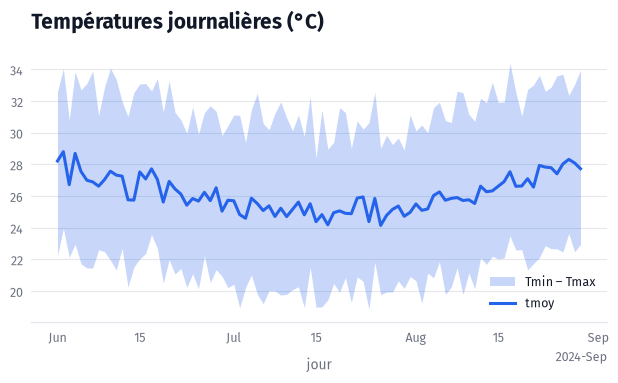

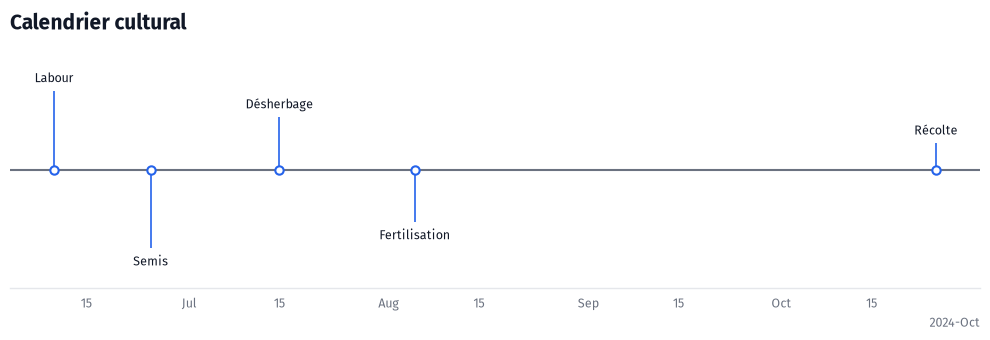

In [3]:
rng = np.random.default_rng(21)
t = np.arange(90)
meteo = pd.DataFrame({'jour': pd.date_range('2024-06-01', periods=90, freq='D'),
                      'tmoy': 28 - 3 * np.sin(t / 90 * np.pi) + rng.normal(0, 0.6, 90)})
meteo['tmin'] = meteo['tmoy'] - rng.uniform(4, 6, 90)
meteo['tmax'] = meteo['tmoy'] + rng.uniform(4, 7, 90)

(Chart(meteo)
    .band('jour', 'tmin', 'tmax', y='tmoy', label='Tmin – Tmax')
    .title('Températures journalières (°C)')
    .tight_layout()
    .show())

calendrier = pd.DataFrame({
    'date': pd.to_datetime(['2024-06-10', '2024-06-25', '2024-07-15', '2024-08-05', '2024-10-25']),
    'etape': ['Labour', 'Semis', 'Désherbage', 'Fertilisation', 'Récolte']})
(Chart(calendrier, figsize=(10, 3.5))
    .timeline('date', 'etape')
    .title('Calendrier cultural')
    .tight_layout()
    .show())

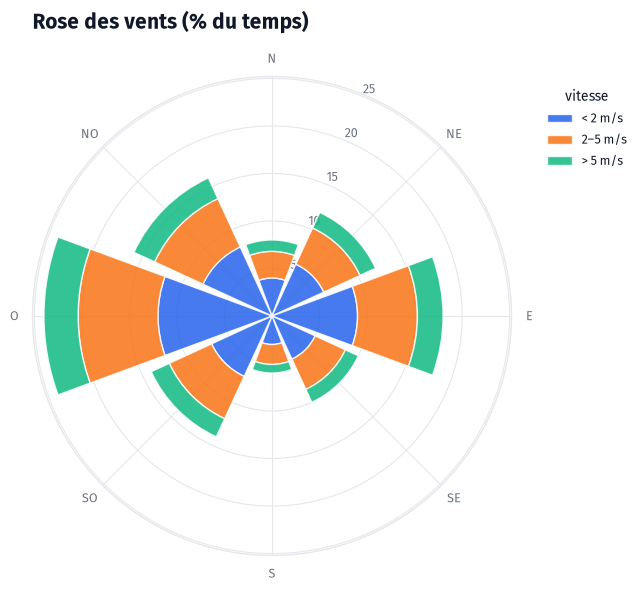

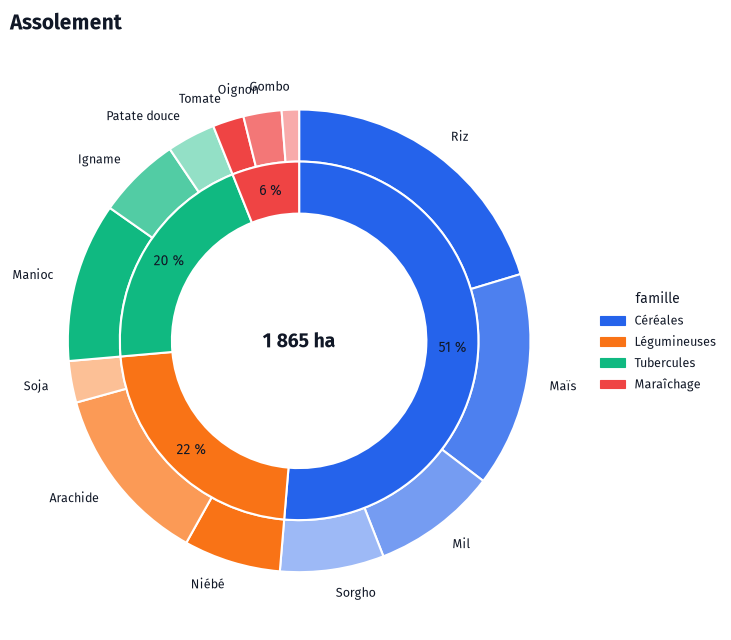

In [4]:
directions = ['N', 'NE', 'E', 'SE', 'S', 'SO', 'O', 'NO']
rose = pd.DataFrame([(d, v, f) for d, base in zip(directions, [4, 6, 9, 5, 3, 7, 12, 8])
                     for v, f in zip(['< 2 m/s', '2–5 m/s', '> 5 m/s'], [base, base * .7, base * .3])],
                    columns=['direction', 'vitesse', 'frequence'])
(Chart(rose, figsize=(6.5, 6.5))
    .polar('direction', 'frequence', group='vitesse', compass=True)
    .title('Rose des vents (% du temps)')
    .tight_layout()
    .show())

(Chart(cultures, figsize=(8, 6.5))
    .donut('surface', labels='culture', group='famille', center_text='1 865 ha')
    .title('Assolement')
    .tight_layout()
    .show())

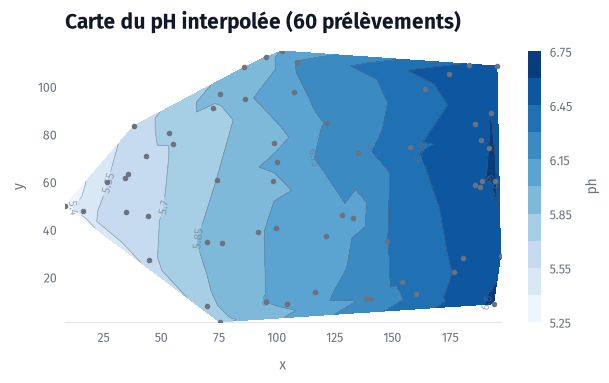

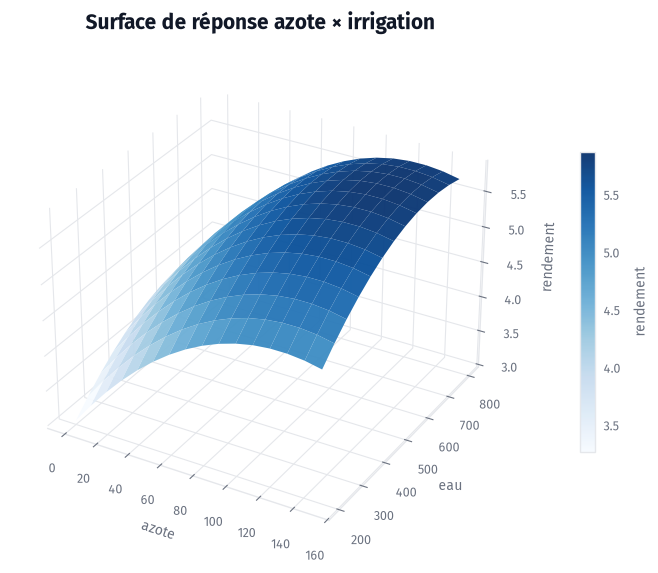

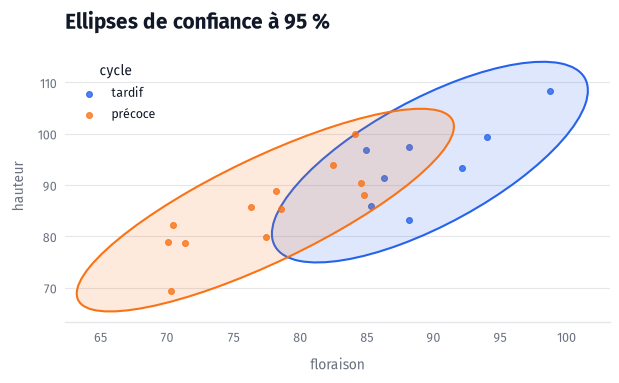

In [5]:
rng = np.random.default_rng(4)
x, y = rng.uniform(0, 200, 60), rng.uniform(0, 120, 60)
champ = pd.DataFrame({'x': x, 'y': y, 'ph': 5.4 + 0.006 * x + rng.normal(0, 0.05, 60)})
(Chart(champ)
    .contour('x', 'y', 'ph', show_points=True)
    .title('Carte du pH interpolée (60 prélèvements)')
    .tight_layout()
    .show())

az, eau = np.meshgrid(np.linspace(0, 150, 16), np.linspace(200, 800, 13))
reponse = pd.DataFrame({'azote': az.ravel(), 'eau': eau.ravel()})
reponse['rendement'] = (2 + 0.03 * reponse['azote'] - 0.00012 * reponse['azote'] ** 2
                        + 0.006 * reponse['eau'] - 0.0000045 * reponse['eau'] ** 2)
(Chart(reponse, figsize=(9, 6.5))
    .surface('azote', 'eau', 'rendement')
    .title('Surface de réponse azote × irrigation')
    .show())

(Chart(caracteres)
    .confidence_ellipse('floraison', 'hauteur', group='cycle')
    .title('Ellipses de confiance à 95 %')
    .tight_layout()
    .show())